# Mandatory assignment 3

**GitHub repository:** https://github.com/maks0n1337/TECH2-H26_Assignment3.git*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [1]:
file ='SCF_10pct.csv'
import pandas as pd

df = pd.read_csv(file)

print(f'Number of non-missing values {df.info()}')




<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB
Number of non-missing values None


In [2]:
variables = ['id', 'year', 'age', 'educ', 'stocks', 'equity']

for var in variables:
    rows_before = len(df)
    df = df.dropna(subset=[var])
    rows_after = len(df)
    dropped = rows_before - rows_after
    print(f'{var}: dropped {dropped}, remaining {rows_after}')


id: dropped 0, remaining 5808
year: dropped 0, remaining 5808
age: dropped 0, remaining 5808
educ: dropped 16, remaining 5792
stocks: dropped 18, remaining 5774
equity: dropped 16, remaining 5758


In [3]:
rows_before = len(df)
df = df[(df['age'] >= 25) & (df['age'] <= 89)]
rows_after = len(df)
dropped = rows_before - rows_after
print(f'Age filter: dropped {dropped}, remaining {rows_after}')

Age filter: dropped 326, remaining 5432


In [ ]:
df['direct'] = (df['stocks'] > 0).astype(int)
df['overall'] = (df['equity'] > 0).astype(int)

df



,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...
5802,5802,2022,77,3.0,0.0,0.0,0,0
5804,5804,2022,33,3.0,0.0,0.0,0,0
5805,5805,2022,81,2.0,100000.0,100000.0,1,1
5806,5806,2022,58,3.0,40000.0,1212000.0,1,1


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [5]:
#1
def participation_rate(indicator):
    ones = 0
    for value in indicator:
        if value == 1:
            ones = ones + 1
    return ones / len(indicator) * 100

print(f'{participation_rate([1,0])}%') #example with 1 and 0

50.0%


In [6]:
#2
direct_part_rate = participation_rate(df['direct'])
overall_part_rate = participation_rate(df['overall'])

print(f'Direct participation rate {direct_part_rate:.2f}%')
print(f'Overall participation rate {overall_part_rate:.2f}%')

Direct participation rate 16.96%
Overall participation rate 49.41%


In [7]:
direct_part_rate = df['direct'].mean() * 100
overall_part_rate = df['overall'].mean() * 100

print(f'Direct participation rate {direct_part_rate:.2f}%')
print(f'Overall participation rate {overall_part_rate:.2f}%')


Direct participation rate 16.96%
Overall participation rate 49.41%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [30]:
for level_of_educ in range(1, 5):
    group = df[df['educ'] == level_of_educ]
    direct_part_rate = group['direct'].mean() * 100
    overall_part_rate = group['overall'].mean() * 100
    print(f'Education {level_of_educ}: Direct particiaption {direct_part_rate:1f}%, and overall participation {overall_part_rate:.1f}%')

Education 1: Direct particiaption 4.444444%, and overall participation 17.3%
Education 2: Direct particiaption 11.390812%, and overall participation 39.9%
Education 3: Direct particiaption 13.523392%, and overall participation 48.3%
Education 4: Direct particiaption 30.467836%, and overall participation 73.5%


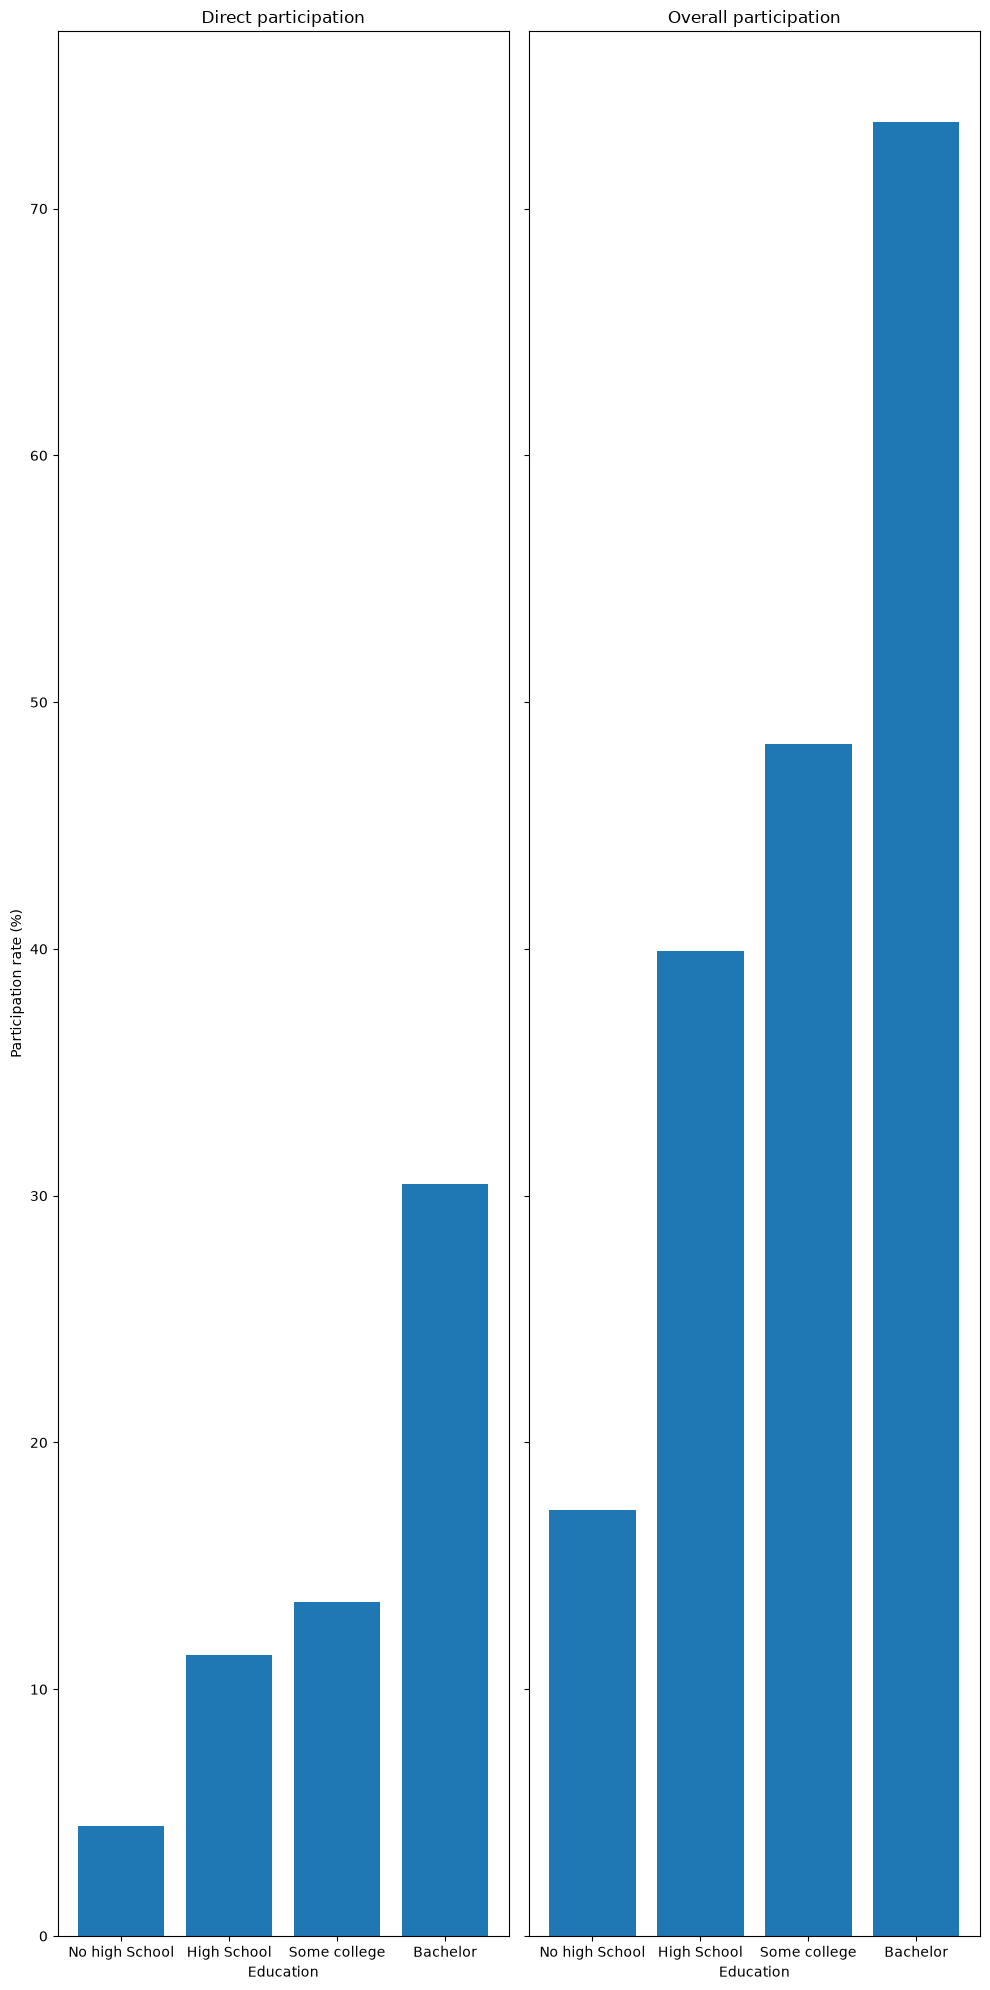

In [9]:
import matplotlib.pyplot as plt
import numpy as np


lst_direct = []
lst_overall = []

for level_of_educ in range(1, 5):
    group = df[df['educ'] == level_of_educ]
    lst_direct.append((group['direct'].mean() * 100))
    lst_overall.append((group['overall'].mean() * 100))

fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(10, 20.0))
labels = ['No high School', 'High School', 'Some college', 'Bachelor']

axes[0].bar(labels, lst_direct)
axes[0].set_title('Direct participation')
axes[0].set_xlabel('Education')
axes[0].set_ylabel('Participation rate (%)')

axes[1].bar(labels, lst_overall)
axes[1].set_title('Overall participation')
axes[1].set_xlabel('Education')

plt.tight_layout()

plt.show()

Stock market participation rises with the level of  education. For example direct participation goes from 4.4% for households without a high school degree to 30.5% for those with a bachelor’s degree or higher, and overall participation from 17.3% to 73.5% 


***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [38]:
lst_direct = []
lst_overall = []
years = sorted(df['year'].unique())

for year in years:
    group = df[df['year'] == year]
    direct_part_rate = group['direct'].mean() * 100
    overall_part_rate = group['overall'].mean() * 100
    lst_direct.append(direct_part_rate)
    lst_overall.append(overall_part_rate)
    print(f'Year {year}: Direct participation {direct_part_rate:.1f}%, and overall participation {overall_part_rate:.1f}%')

#ai recommended to use built in function "unique()" and "sorted"

Year 1989: Direct participation 15.6%, and overall participation 31.6%
Year 1992: Direct participation 18.3%, and overall participation 40.1%
Year 1995: Direct participation 15.7%, and overall participation 45.9%
Year 1998: Direct participation 19.9%, and overall participation 51.2%
Year 2001: Direct participation 21.8%, and overall participation 57.0%
Year 2004: Direct participation 18.9%, and overall participation 54.7%
Year 2007: Direct participation 17.3%, and overall participation 56.5%
Year 2010: Direct participation 17.4%, and overall participation 50.3%
Year 2013: Direct participation 14.8%, and overall participation 49.9%
Year 2016: Direct participation 12.3%, and overall participation 52.0%
Year 2019: Direct participation 12.4%, and overall participation 49.8%
Year 2022: Direct participation 19.2%, and overall participation 54.3%


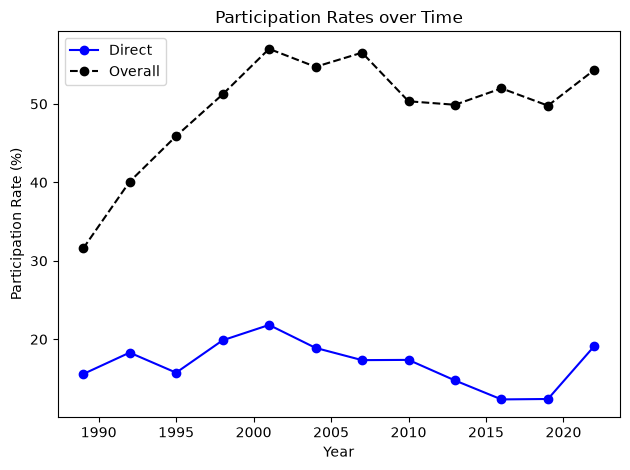

In [39]:
plt.plot(years, lst_direct, 'b-', marker ='o', label = "Direct")
plt.plot(years, lst_overall, 'k--', marker = 'o',label = "Overall")

plt.xlabel('Year')
plt.ylabel('Participation Rate (%)')
plt.title('Participation Rates over Time')




plt.tight_layout()
plt.legend()


In [40]:
first_dir_rate = lst_direct[0]
last_dir_rate = lst_direct[-1]
change_direct = last_dir_rate - first_dir_rate

first_over_rate = lst_overall[0]
last_over_rate = lst_overall[-1]
change_overall = last_over_rate - first_over_rate

print(f'Change in direct participation (1989 and 2022): {change_direct:+.1f}%, change in overall participation rate {change_overall:+.1f}% ')


Change in direct participation (1989 and 2022): +3.6%, change in overall participation rate +22.8% 


From 1989 to 2022, overall participation rose by 22.8 per cent, while direct participation rose by only 3.6 pper cent. The gap between the two rates is wide, which suggests that the growth in stock market participation came mainly through indirect holdings rather than direct stock ownership

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I was stuck on part 1 (fourth question) and i used claude AI, which recomemnded me to add "astype(int) to turn columns from True/False to 0/1. The rest was completed bymyself, using past materials from workshops and lessons